# Logistic regression: which tracks should we push?
**Question:** Which features make a hit more likely, and what cut-off should we use to decide which tracks to push?

The OLS model (`regression-fit.ipynb`) predicts a popularity *score*. A label's actual decision is yes/no: push a track or not. This notebook models that decision directly:
- the target is `hit` (1 = top 10% of popularity, 0 = otherwise)
- the output is a **probability of being a hit per song**, plus **odds ratios** showing which features raise or lower the odds
- the decision rule is **"push tracks whose predicted hit probability is above X%"**, with X chosen on training data and checked on unseen artists
- an **artist track-record feature** (how the artist's other songs performed) is added on top of genre and audio, because who releases a track is the largest driver the OLS model was missing

Run `bt4211-project.ipynb` first; it saves `tracks_clean.pkl`. Run `regression-fit.ipynb` first too if you want the OLS comparison in section 4.

# 1) Imports and data

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import statsmodels.formula.api as smf
from patsy import dmatrices
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, log_loss,
                             roc_curve, precision_recall_curve, confusion_matrix)
from sklearn.calibration import calibration_curve
from IPython.display import display
SEED = 42
Path("figures").mkdir(exist_ok=True); Path("outputs").mkdir(exist_ok=True)
BLUE, ORANGE, MUTED = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e1", "axes.titleweight": "bold", "figure.dpi": 110})

tracks = pd.read_pickle("tracks_clean.pkl")
tracks["artist"] = tracks["artists"].str.split(";").str[0].str.strip()
tracks["track_index"] = tracks.index    # row key into the genre weights below
print(f"{len(tracks):,} songs")

81,343 songs


# 2) Defining a hit
- **Popularity-0 songs are left out**, as in the OLS model: they are mostly a collection artefact (EDA E1, E4). Section 7 checks what happens if they are kept.
- **Same train/test split as OLS:** 80/20 by artist with the same seed, so the test set is the same unseen artists and the two models can be compared song for song.
- **Hit = popularity at or above the 90th percentile of the *training* set.** Taking the cut-off from training data only keeps the test set untouched. Top 10% is a judgement call (a label can only push a small share of its catalogue), so section 7 repeats the analysis with top 5% and top 20%.

hit = popularity >= 61


,songs,hits,hit_rate
in_test_set,,,
train,61513,6732,0.109
test,15072,1731,0.115


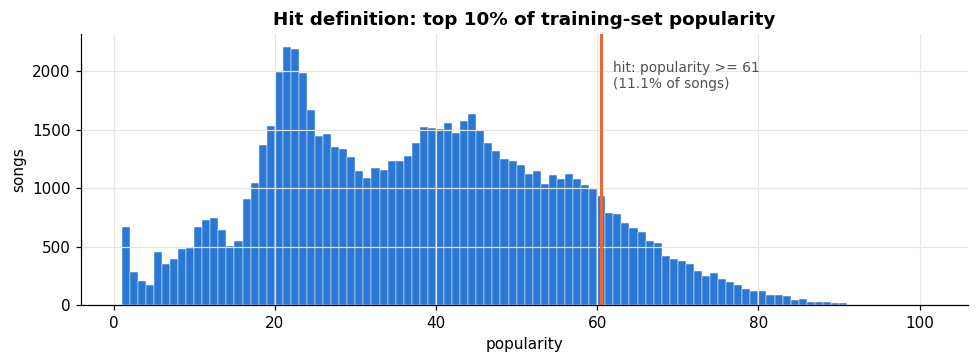

In [2]:
def split(df):
    tr_i, te_i = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(df, groups=df["artist"]))
    return df.index.isin(df.index[te_i])

t = tracks[tracks["popularity"] > 0].reset_index(drop=True).copy()
t["in_test_set"] = split(t)
HIT_Q = 0.90
HIT_THR = t.loc[~t["in_test_set"], "popularity"].quantile(HIT_Q)
t["hit"] = (t["popularity"] >= HIT_THR).astype(int)
print(f"hit = popularity >= {HIT_THR:.0f}")
display(t.groupby("in_test_set")["hit"].agg(songs="size", hits="sum", hit_rate="mean")
          .rename(index={False: "train", True: "test"}).round(3))

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(t["popularity"], bins=range(1, 102), color=BLUE, edgecolor="#fcfcfb", linewidth=0.3)
ax.axvline(HIT_THR - 0.5, color=ORANGE, lw=2)
ax.text(HIT_THR + 1, ax.get_ylim()[1] * 0.9, f"hit: popularity >= {HIT_THR:.0f}\n({t['hit'].mean():.1%} of songs)", color=MUTED, fontsize=9, va="top")
ax.set_xlabel("popularity"); ax.set_ylabel("songs"); ax.set_title("Hit definition: top 10% of training-set popularity")
fig.tight_layout(); plt.savefig("figures/logit_01_hit_definition.png", dpi=150, bbox_inches="tight"); plt.show()

Ties at the cut-off push the hit rate slightly above 10%. With roughly 1 hit for every 8 non-hits, accuracy is a misleading score: predicting "no hit" for every song is already ~89% accurate. Models are therefore judged on **ROC AUC** (ranking), **average precision** (precision across the ranking, against the hit rate as baseline) and the **Brier score** (how accurate the probabilities are).

# 3) Features
Same features as the OLS model, so the two are comparable:
- $\log_2$ for the skewed features (duration capped at p99.5, speechiness, liveness), and flags for explicit, collaboration, 4/4 time and non-music
- the same three squared terms and three interactions
- genre as fractional multi-hot weights, with `pop` as the reference

Two changes:
- **Scaling and the duration cap are fitted on the training set only**, so nothing about the test songs leaks into the features.
- **Genres with fewer than 10 training hits are pooled** into one `g_low_hit_pool` weight. Several genres (e.g. study, grindcore, detroit-techno) have no hits at all. For those, the logistic coefficient goes to minus infinity (perfect separation) and the fit fails. Pooling keeps every song and states the honest finding: "these genres almost never produce hits". Section 7 checks the pooling against a penalised model that keeps every genre separate.
- The k-means sound clusters are dropped. They added only 0.002 test $R^2$ in the OLS model, and they are built from the audio features the model already has.

**New: artist track record.** For each song, this is the average popularity of the same (primary) artist's **other** songs, leaving the song itself out:
- **Why "other songs" and not an artist average from training:** the split is by artist, so test artists never appear in training. A training-set artist average would be empty for every test song. Using the artist's other songs mirrors what a label actually knows before pushing a track by an existing artist: how their catalogue has done. Because the song's own popularity is always excluded, its label never enters its own feature.
- **Shrinkage:** an artist with one other song gives a noisy average, so the average is shrunk toward the training mean: $\frac{\text{sum of other songs} + m \cdot \text{prior}}{n_\text{other} + m}$, with $m = 5$. An artist needs about five other songs before their own record outweighs the overall average.
- **Two companion terms:** `artist_new` flags songs whose artist has no other song in the data (debut-like; the feature then equals the prior), and $\log_2(1 + n_\text{other})$ measures catalogue size, since prolific catalogue acts are often *less* popular (EDA E5).
- **Caveat:** the snapshot has no release dates, so "other songs" can include songs released *after* this one. A real deployment would use only earlier releases.

In [3]:
AUDIO = ["danceability", "energy", "loudness", "log_speechiness", "acousticness",
         "instrumentalness", "log_liveness", "valence", "tempo", "log_duration"]
ARTIST_M = 5                                       # shrinkage strength (pseudo-songs at the prior)
SCALED = AUDIO + ["artist_pop", "artist_catalogue"]
GENRE_W = pd.get_dummies(tracks["genres"].explode().replace({"songwriter": "singer-songwriter"})).groupby(level=0).max().astype(float)
GENRE_W.columns = ["g_" + c.replace("-", "_") for c in GENRE_W.columns]
GENRE_W = GENRE_W.div(GENRE_W.sum(axis=1), axis=0)   # fractional weights, indexed like `tracks`

def build_features(df, min_hits=10):
    # fit every transform on the training rows only
    df = df.copy()
    tr = ~df["in_test_set"]
    df["log_duration"] = np.log2(df["duration_min"].clip(upper=df.loc[tr, "duration_min"].quantile(0.995)))
    df["log_speechiness"] = np.log2(df["speechiness"] + 0.01)
    df["log_liveness"] = np.log2(df["liveness"] + 0.01)
    df["tempo"] = df["tempo"].fillna(df.loc[tr, "tempo"].median())    # undefined only for non_music tracks
    df["is_4_4"] = df["time_signature"].eq(4).fillna(False).astype(int)
    for c in ["explicit", "collab", "non_music"]:
        df[c] = df[c].astype(int)
    # artist track record: shrunken mean popularity of the same primary artist's *other* songs (own song left out)
    assert df.groupby("artist")["in_test_set"].nunique().max() == 1    # no artist straddles the split
    g = df.groupby("artist")["popularity"]
    n_other = g.transform("size") - 1
    prior = df.loc[tr, "popularity"].mean()
    df["artist_pop"] = (g.transform("sum") - df["popularity"] + ARTIST_M * prior) / (n_other + ARTIST_M)
    df["artist_catalogue"] = np.log2(1 + n_other)
    df["artist_new"] = (n_other == 0).astype(int)

    mu, sd = df.loc[tr, SCALED].mean(), df.loc[tr, SCALED].std()
    for c in SCALED:
        df["z_" + c] = (df[c] - mu[c]) / sd[c]

    W = GENRE_W.loc[df["track_index"]].reset_index(drop=True)
    pooled = []
    if min_hits:
        hits = (W[tr.values] > 0).mul(df.loc[tr, "hit"].values, axis=0).sum()
        pooled = [g for g in hits[hits < min_hits].index if g != "g_pop"]
        W["g_low_hit_pool"] = W[pooled].sum(axis=1)
        W = W.drop(columns=pooled)
    df = pd.concat([df.reset_index(drop=True), W], axis=1)
    return df, [c for c in W.columns if c != "g_pop"], pooled

t, GENRES, POOLED = build_features(t)
print(f"{len(AUDIO)} audio features, {len(GENRES)} genre terms (reference: pop)")
print(f"{len(POOLED)} genres pooled into g_low_hit_pool: {', '.join(g[2:] for g in POOLED)}")
print(f"songs whose artist has no other song (artist_new): {t['artist_new'].mean():.1%}")
display(t.groupby("artist_new")[["artist_pop", "popularity", "hit"]].mean().rename(index={0: "returning artist", 1: "new artist"}).round(3))

10 audio features, 75 genre terms (reference: pop)
38 genres pooled into g_low_hit_pool: afrobeat, black_metal, bluegrass, brazil, breakbeat, cantopop, chicago_house, club, comedy, death_metal, detroit_techno, drum_and_bass, forro, gospel, goth, grindcore, guitar, happy, heavy_metal, honky_tonk, idm, iranian, j_idol, kids, malay, minimal_techno, mpb, new_age, opera, pagode, party, romance, salsa, samba, sertanejo, ska, study, tango
songs whose artist has no other song (artist_new): 9.5%


,artist_pop,popularity,hit
artist_new,,,
returning artist,37.016,37.172,0.109
new artist,37.573,39.970,0.127


# 4) Model fitting
The models are built up in blocks, as in the OLS notebook, so each row shows what one block adds. Standard errors are clustered by artist. Reference points:
- **Genre only** and **artist only:** how far each gets on its own.
- **OLS ranking:** the OLS model's predicted popularity used as a hit score (from `outputs/ols_predictions.csv`, same test songs). This tests whether modelling the yes/no decision directly beats ranking by a predicted score.

In [4]:
BASE = " + ".join("z_" + c for c in AUDIO) + " + explicit + collab + is_4_4 + non_music"
SQ = " + I(z_danceability**2) + I(z_acousticness**2) + I(z_log_duration**2)"
INTER = " + z_danceability:z_valence + z_energy:z_acousticness + explicit:z_danceability"
GENRE = " + " + " + ".join(GENRES)
ARTIST = " + z_artist_pop + z_artist_catalogue + artist_new"
FORMULAS = {
    "1. audio + flags": "hit ~ " + BASE,
    "2. + squares + interactions": "hit ~ " + BASE + SQ + INTER,
    "genre only": "hit ~ " + " + ".join(GENRES),
    "artist only": "hit ~ " + ARTIST[3:],
    "3. + genre": "hit ~ " + BASE + SQ + INTER + GENRE,
    "4. + artist (final)": "hit ~ " + BASE + SQ + INTER + GENRE + ARTIST,
}
train, test = t[~t["in_test_set"]], t[t["in_test_set"]]

def fit_logit(f, df, robust=True):
    kw = {"cov_type": "cluster", "cov_kwds": {"groups": pd.factorize(df["artist"])[0]}} if robust else {}
    return smf.logit(f, df).fit(disp=0, maxiter=200, **kw)

def scores(y, p):
    return {"test_AUC": roc_auc_score(y, p), "test_avg_precision": average_precision_score(y, p),
            "test_Brier": brier_score_loss(y, p), "test_log_loss": log_loss(y, p)}

fits, rows = {}, []
for name, f in FORMULAS.items():
    res = fit_logit(f, train)
    assert res.mle_retvals["converged"], name
    fits[name] = res
    rows.append({"model": name, "params": len(res.params), "train_pseudo_R2": res.prsquared, **scores(test["hit"], res.predict(test))})

ols_path = Path("outputs/ols_predictions.csv")
if ols_path.exists():
    ols = test[["track_id"]].merge(pd.read_csv(ols_path), on="track_id", how="left")
    assert ols["in_test_set"].all(), "OLS test set differs; re-run regression-fit.ipynb"
    rows.append({"model": "OLS predicted popularity (ranking only)",
                 "test_AUC": roc_auc_score(test["hit"], ols["predicted_popularity"]),
                 "test_avg_precision": average_precision_score(test["hit"], ols["predicted_popularity"])})
rows.append({"model": "no model (hit rate)", "test_avg_precision": test["hit"].mean(),
             "test_Brier": brier_score_loss(test["hit"], np.full(len(test), train["hit"].mean()))})
model_tbl = pd.DataFrame(rows).set_index("model")
display(model_tbl.round(4))
final = fits["4. + artist (final)"]

,params,train_pseudo_R2,test_AUC,test_avg_precision,test_Brier,test_log_loss
model,,,,,,
1. audio + flags,15.0,0.0479,0.6900,0.2183,0.0970,0.3338
2. + squares + interactions,21.0,0.0565,0.7037,0.2227,0.0964,0.3298
genre only,76.0,0.3492,0.8760,0.5080,0.0751,0.2461
artist only,4.0,0.3359,0.9006,0.6076,0.0662,0.2259
3. + genre,96.0,0.3591,0.8850,0.5332,0.0734,0.2407
4. + artist (final),99.0,0.4487,0.9286,0.6701,0.0598,0.1970
OLS predicted popularity (ranking only),NaN,NaN,0.8491,0.4715,NaN,NaN
no model (hit rate),NaN,NaN,NaN,0.1148,0.1017,NaN


## 4b) Who does the artist feature help?
The artist record only exists for returning artists. For songs by artists with no other track, the final model falls back on genre and audio. The table splits the test set accordingly.

In [5]:
rows = []
for label, m in [("returning artist", test["artist_new"] == 0), ("new artist", test["artist_new"] == 1)]:
    sub = test[m]
    for name in ["3. + genre", "4. + artist (final)"]:
        rows.append({"test songs": label, "model": name, "songs": len(sub), "hit_rate": sub["hit"].mean(),
                     "AUC": roc_auc_score(sub["hit"], fits[name].predict(sub)),
                     "avg_precision": average_precision_score(sub["hit"], fits[name].predict(sub))})
display(pd.DataFrame(rows).set_index(["test songs", "model"]).round(3))

songs  hit_rate    AUC  avg_precision
test songs       model                                                     
returning artist 3. + genre           13567     0.114  0.888          0.533
                 4. + artist (final)  13567     0.114  0.934          0.683
new artist       3. + genre            1505     0.124  0.877          0.556
                 4. + artist (final)   1505     0.124  0.876          0.561

# 5) Which features raise or lower the odds?
An **odds ratio** (OR) above 1 raises the odds of a hit and below 1 lowers them. For the standardised audio features, the OR is per 1 SD increase. For flags, it compares yes vs no. The 95% CIs use artist-clustered standard errors.

Danceability, acousticness and duration also have squared terms, so their main OR applies at the average value. Their full shape is in the effect curves below.

,odds_ratio,ci_low,ci_high,p
label,,,,
non-music,0.187,0.058,0.601,0.005
artist catalogue size (log),0.527,0.472,0.588,0.000
acousticness,0.852,0.787,0.923,0.000
new artist (no other songs),0.890,0.772,1.026,0.108
duration²,0.904,0.877,0.933,0.000
energy,0.910,0.837,0.989,0.026
energy × acousticness,0.924,0.864,0.989,0.023
instrumentalness,0.926,0.868,0.989,0.021
duration (log),0.929,0.880,0.980,0.007


,OR without artist,OR with artist
danceability,1.078,1.040
energy,0.816,0.910
loudness,1.132,1.004
speechiness (log),0.960,0.977
acousticness,0.839,0.852
instrumentalness,0.899,0.926
liveness (log),0.929,0.951
valence,1.049,1.100
tempo,0.966,0.966
duration (log),0.937,0.929


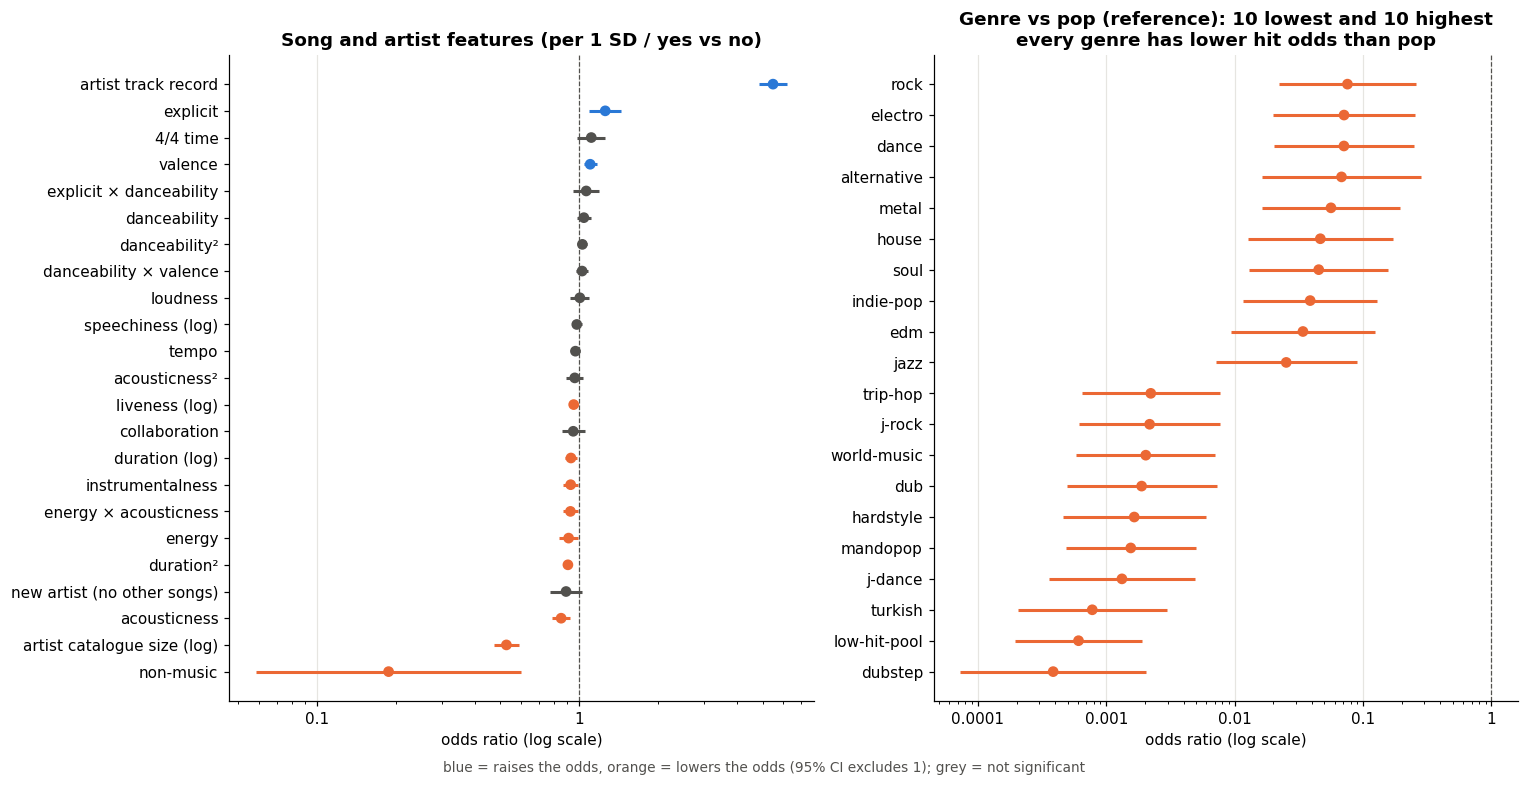

In [6]:
ci = np.exp(final.conf_int())
odds = pd.DataFrame({"coef": final.params, "odds_ratio": np.exp(final.params), "ci_low": ci[0], "ci_high": ci[1],
                     "p": final.pvalues}).rename_axis("term")
odds.to_csv("outputs/logit_odds_ratios.csv")

LABELS = {"z_danceability": "danceability", "z_energy": "energy", "z_loudness": "loudness",
          "z_log_speechiness": "speechiness (log)", "z_acousticness": "acousticness",
          "z_instrumentalness": "instrumentalness", "z_log_liveness": "liveness (log)", "z_valence": "valence",
          "z_tempo": "tempo", "z_log_duration": "duration (log)", "explicit": "explicit", "collab": "collaboration",
          "is_4_4": "4/4 time", "non_music": "non-music",
          "I(z_danceability ** 2)": "danceability²", "I(z_acousticness ** 2)": "acousticness²",
          "I(z_log_duration ** 2)": "duration²", "z_danceability:z_valence": "danceability × valence",
          "z_energy:z_acousticness": "energy × acousticness", "explicit:z_danceability": "explicit × danceability",
          "z_artist_pop": "artist track record", "z_artist_catalogue": "artist catalogue size (log)",
          "artist_new": "new artist (no other songs)"}
feat = odds.loc[list(LABELS)].assign(label=lambda d: d.index.map(LABELS)).sort_values("odds_ratio")
display(feat.set_index("label")[["odds_ratio", "ci_low", "ci_high", "p"]].round(3))

# how much of each song-level effect was really the artist? compare odds ratios before and after adding the artist block
prev = fits["3. + genre"]
shift = pd.DataFrame({"OR without artist": np.exp(prev.params), "OR with artist": np.exp(final.params)}).loc[
    [k for k in LABELS if k in prev.params]].rename(index=LABELS)
display(shift.round(3))

def forest(ax, d, title):
    y = np.arange(len(d))
    sig = (d["ci_low"] > 1) | (d["ci_high"] < 1)
    colors = np.where(~sig, MUTED, np.where(d["odds_ratio"] > 1, BLUE, ORANGE))
    ax.hlines(y, d["ci_low"], d["ci_high"], color=colors, lw=2)
    ax.scatter(d["odds_ratio"], y, color=colors, s=36, zorder=3)
    ax.axvline(1, color=MUTED, lw=0.8, ls="--")
    ax.set_xscale("log"); ax.xaxis.set_major_formatter(mtick.FormatStrFormatter("%g"))
    ax.set_yticks(y); ax.set_yticklabels(d["label"]); ax.grid(axis="y", visible=False)
    ax.set_xlabel("odds ratio (log scale)"); ax.set_title(title)

genre_or = odds.loc[GENRES].assign(label=lambda d: d.index.str[2:].str.replace("_", "-"))
genre_show = pd.concat([genre_or.nsmallest(10, "odds_ratio"), genre_or.nlargest(10, "odds_ratio")]).sort_values("odds_ratio")
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
forest(axes[0], feat, "Song and artist features (per 1 SD / yes vs no)")
forest(axes[1], genre_show, "Genre vs pop (reference): 10 lowest and 10 highest\nevery genre has lower hit odds than pop")
fig.text(0.5, -0.01, "blue = raises the odds, orange = lowers the odds (95% CI excludes 1); grey = not significant",
         ha="center", color=MUTED, fontsize=9)
fig.tight_layout(); plt.savefig("figures/logit_02_odds_ratios.png", dpi=150, bbox_inches="tight"); plt.show()

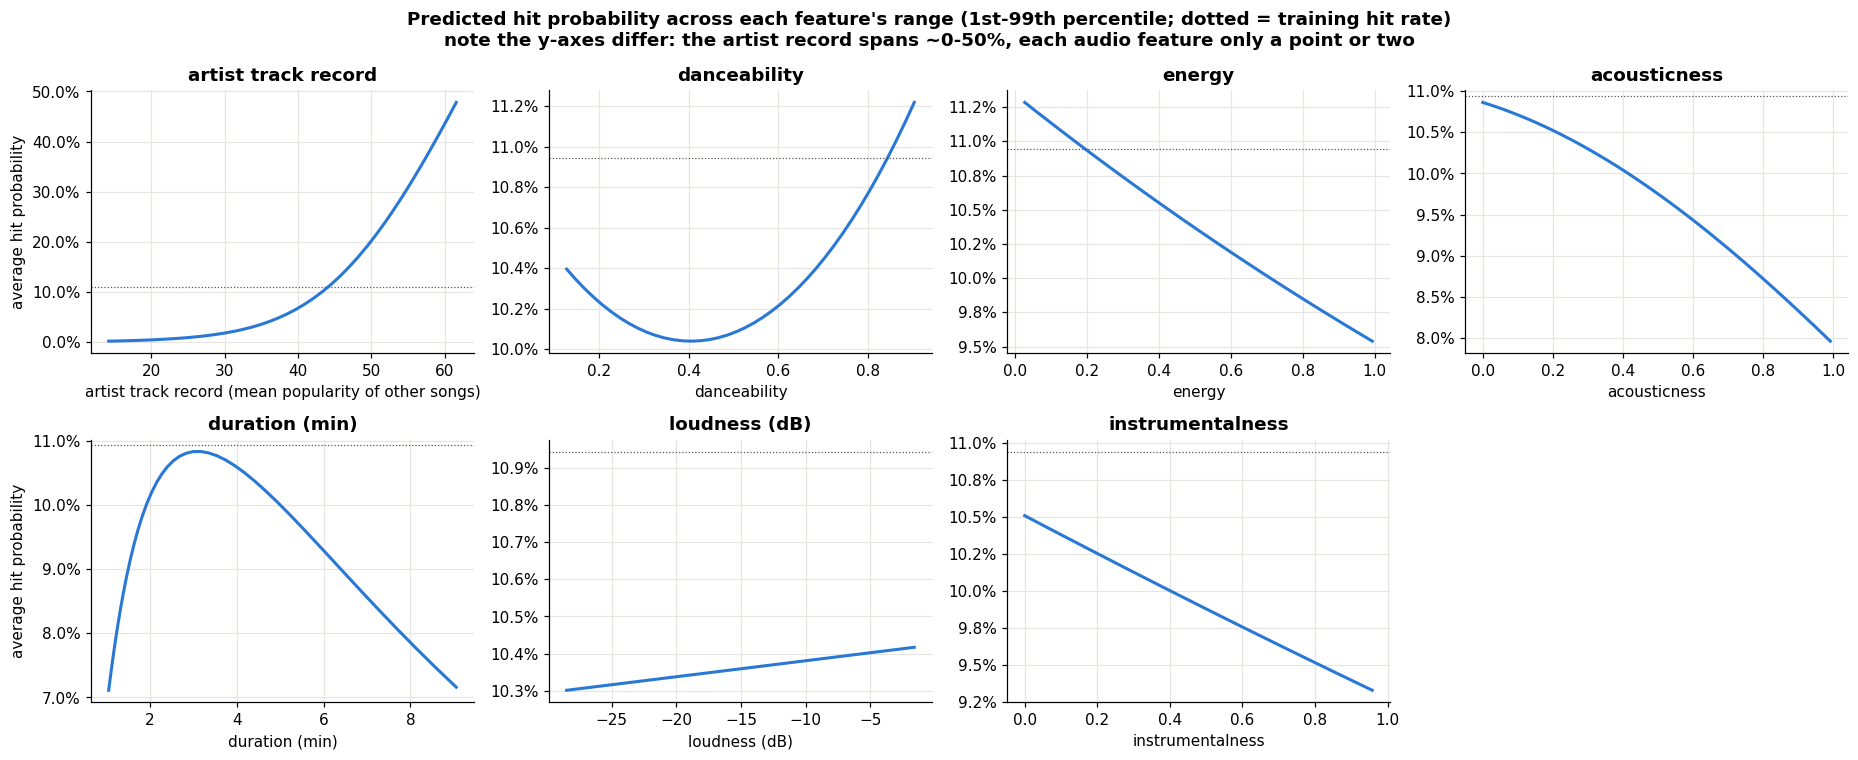

In [7]:
# effect curves: average predicted hit probability as one feature moves across its range, all else as observed
CURVES = [("artist_pop", "artist track record (mean popularity of other songs)"), ("danceability", "danceability"),
          ("energy", "energy"), ("acousticness", "acousticness"),
          ("log_duration", "duration (min)"), ("loudness", "loudness (dB)"), ("instrumentalness", "instrumentalness")]
mu, sd = train[SCALED].mean(), train[SCALED].std()
base = train.sample(5_000, random_state=SEED)
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
axes.flat[-1].axis("off")
for ax, (col, label) in zip(axes.flat, CURVES):
    lo, hi = train[col].quantile([0.01, 0.99])
    grid = np.linspace(lo, hi, 40)
    prob = [final.predict(base.assign(**{"z_" + col: (g - mu[col]) / sd[col]})).mean() for g in grid]
    x = 2 ** grid if col == "log_duration" else grid
    ax.plot(x, prob, color=BLUE, lw=2)
    ax.axhline(train["hit"].mean(), color=MUTED, lw=0.8, ls=":")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=1))
    ax.set_xlabel(label); ax.set_title(label.split(" (mean")[0])
axes[0, 0].set_ylabel("average hit probability"); axes[1, 0].set_ylabel("average hit probability")
fig.suptitle("Predicted hit probability across each feature's range (1st-99th percentile; dotted = training hit rate)\nnote the y-axes differ: the artist record spans ~0-50%, each audio feature only a point or two", fontweight="bold")
fig.tight_layout(); plt.savefig("figures/logit_03_effect_curves.png", dpi=150, bbox_inches="tight"); plt.show()

# 6) Choosing the cut-off
The cut-off has to be chosen **without looking at the test set**; otherwise the test result is flattering. So:
1. 5-fold cross-validation on the training set, grouped by artist, gives an out-of-fold hit probability for every training song.
2. Several cut-off rules are compared on those out-of-fold probabilities.
3. The chosen cut-off is then applied once to the test set.

The cut-off rules:
- **Max F1:** the best balance of precision (share of pushed tracks that become hits) and recall (share of hits that get pushed).
- **Youden's J:** maximises true-positive rate minus false-positive rate. It treats a missed hit and a wasted push as equally bad, which pushes far too many tracks when hits are rare.
- **Cost-based break-even:** if pushing a track costs $C$ and a hit is worth $V$, pushing pays off on average whenever $p > C/V$. This needs calibrated probabilities, which logistic regression gives (section 6b). The table shows it for a few cost/value ratios.
- **Capacity:** push only the top $k$% of tracks, if the marketing budget fixes how many can be pushed.

out-of-fold AUC 0.922, average precision 0.665


,cutoff,share_pushed,precision,recall,lift,F1
rule,,,,,,
max F1,0.270,0.134,0.553,0.677,5.057,0.609
Youden's J,0.128,0.234,0.400,0.853,3.653,0.544
"break-even, cost/value = 0.20",0.200,0.171,0.489,0.763,4.465,0.596
"break-even, cost/value = 0.33",0.330,0.109,0.606,0.606,5.538,0.606
"break-even, cost/value = 0.50",0.500,0.068,0.741,0.459,6.775,0.567
capacity: top 5%,0.600,0.050,0.804,0.367,7.343,0.504
capacity: top 10%,0.358,0.100,0.634,0.580,5.796,0.606


chosen cut-off: push if P(hit) >= 0.27


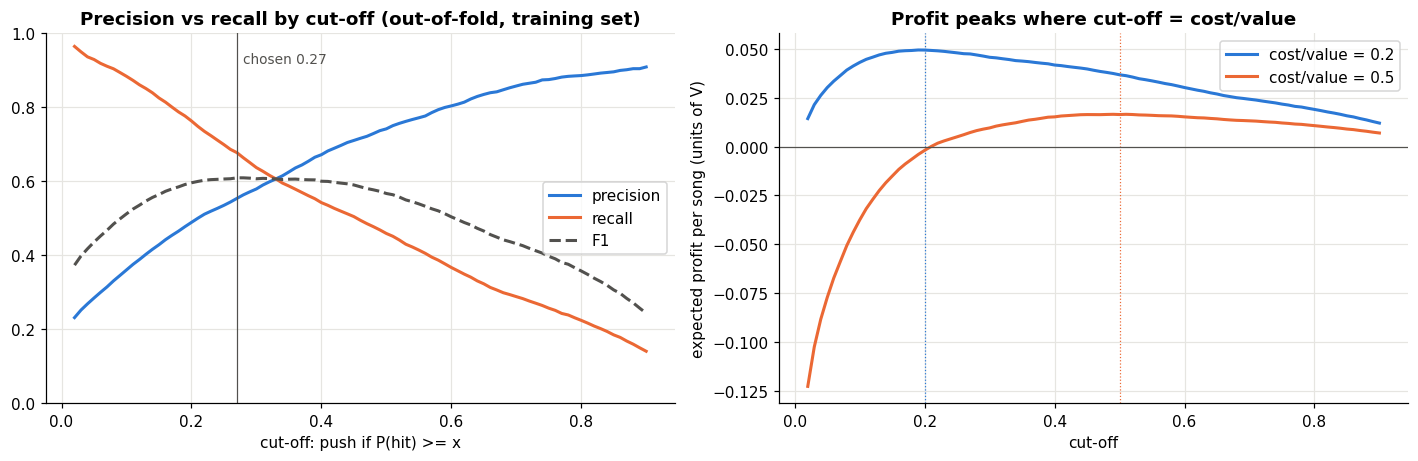

In [8]:
FINAL_F = FORMULAS["4. + artist (final)"]
oof = pd.Series(np.nan, index=train.index)
for k, (a, b) in enumerate(GroupKFold(n_splits=5).split(train, groups=train["artist"])):
    # genre pooling was set on the full training set; refitting it per fold changes the folds very little
    oof.iloc[b] = fit_logit(FINAL_F, train.iloc[a], robust=False).predict(train.iloc[b]).values
y_tr = train["hit"]
print(f"out-of-fold AUC {roc_auc_score(y_tr, oof):.3f}, average precision {average_precision_score(y_tr, oof):.3f}")

def at_cutoff(y, p, c):
    push = p >= c
    tp = (push & (y == 1)).sum()
    prec = tp / max(push.sum(), 1)
    return {"cutoff": c, "share_pushed": push.mean(), "precision": prec, "recall": tp / (y == 1).sum(),
            "lift": prec / y.mean(), "F1": 2 * tp / (push.sum() + (y == 1).sum())}

cands = np.round(np.arange(0.02, 0.91, 0.01), 2)
curve = pd.DataFrame([at_cutoff(y_tr, oof, c) for c in cands])
fpr, tpr, thr = roc_curve(y_tr, oof)
rules = {"max F1": curve.loc[curve["F1"].idxmax(), "cutoff"],
         "Youden's J": thr[np.argmax(tpr - fpr)]}
for cv in [0.2, 0.33, 0.5]:
    rules[f"break-even, cost/value = {cv:.2f}"] = cv
for k in [0.05, 0.10]:
    rules[f"capacity: top {k:.0%}"] = oof.quantile(1 - k)
cut_tbl = pd.DataFrame([{"rule": r, **at_cutoff(y_tr, oof, c)} for r, c in rules.items()]).set_index("rule")
display(cut_tbl.round(3))
CUTOFF = float(rules["max F1"])
print(f"chosen cut-off: push if P(hit) >= {CUTOFF:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for col, c, ls in [("precision", BLUE, "-"), ("recall", ORANGE, "-"), ("F1", MUTED, "--")]:
    axes[0].plot(curve["cutoff"], curve[col], color=c, lw=2, ls=ls, label=col)
axes[0].axvline(CUTOFF, color=MUTED, lw=0.8)
axes[0].text(CUTOFF + 0.01, 0.95, f"chosen {CUTOFF:.2f}", color=MUTED, fontsize=9, va="top")
axes[0].set_xlabel("cut-off: push if P(hit) >= x"); axes[0].set_ylim(0, 1); axes[0].legend(loc="center right")
axes[0].set_title("Precision vs recall by cut-off (out-of-fold, training set)")
for cv, c in [(0.2, BLUE), (0.5, ORANGE)]:
    # expected profit per catalogue song, in units of V: hits pushed earn V, every push costs C
    profit = [((oof >= x) * (y_tr - cv)).mean() for x in cands]
    axes[1].plot(cands, profit, color=c, lw=2, label=f"cost/value = {cv}")
    axes[1].axvline(cv, color=c, lw=0.8, ls=":")
axes[1].axhline(0, color=MUTED, lw=0.8)
axes[1].set_xlabel("cut-off"); axes[1].set_ylabel("expected profit per song (units of V)"); axes[1].legend()
axes[1].set_title("Profit peaks where cut-off = cost/value")
fig.tight_layout(); plt.savefig("figures/logit_04_cutoff.png", dpi=150, bbox_inches="tight"); plt.show()

## 6b) Test set: the chosen cut-off on unseen artists, and probability calibration

,cutoff,share_pushed,precision,recall,lift,F1
set,,,,,,
test (unseen artists),0.27,0.147,0.544,0.699,4.739,0.612
train (out-of-fold),0.27,0.134,0.553,0.677,5.057,0.609


,not pushed,pushed
actual: not hit,12328,1013
actual: hit,521,1210


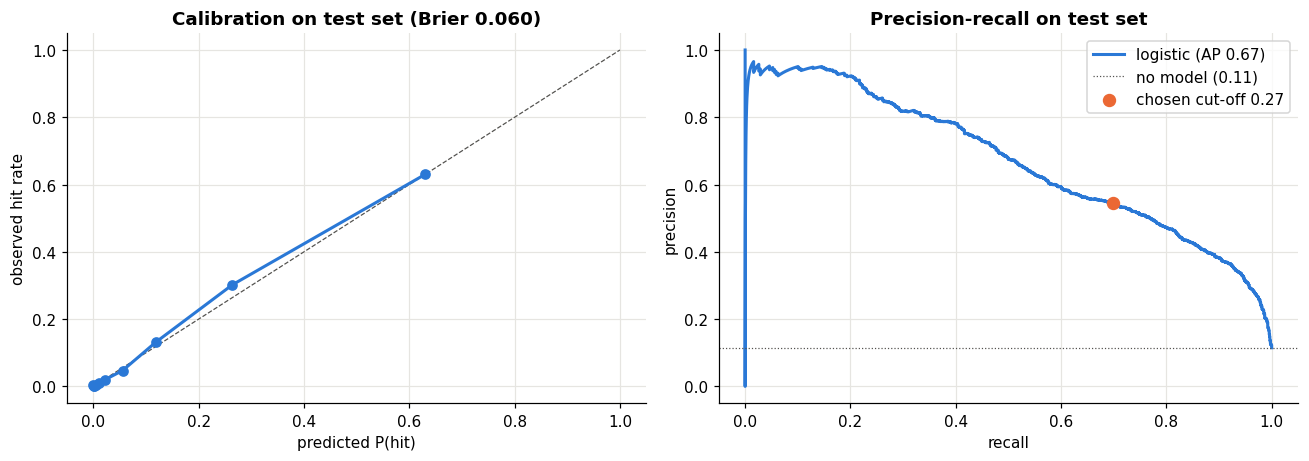

In [9]:
p_test = final.predict(test)
y_te = test["hit"]
test_res = pd.DataFrame([{"set": "test (unseen artists)", **at_cutoff(y_te, p_test, CUTOFF)},
                         {"set": "train (out-of-fold)", **at_cutoff(y_tr, oof, CUTOFF)}]).set_index("set")
display(test_res.round(3))
cm = pd.DataFrame(confusion_matrix(y_te, p_test >= CUTOFF), index=["actual: not hit", "actual: hit"],
                  columns=["not pushed", "pushed"])
display(cm)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
frac, mean_p = calibration_curve(y_te, p_test, n_bins=10, strategy="quantile")
axes[0].plot([0, 1], [0, 1], color=MUTED, lw=0.8, ls="--")
axes[0].plot(mean_p, frac, "o-", color=BLUE, lw=2)
axes[0].set_xlabel("predicted P(hit)"); axes[0].set_ylabel("observed hit rate")
axes[0].set_title(f"Calibration on test set (Brier {brier_score_loss(y_te, p_test):.3f})")
prec, rec, _ = precision_recall_curve(y_te, p_test)
axes[1].plot(rec, prec, color=BLUE, lw=2, label=f"logistic (AP {average_precision_score(y_te, p_test):.2f})")
axes[1].axhline(y_te.mean(), color=MUTED, lw=0.8, ls=":", label=f"no model ({y_te.mean():.2f})")
r = test_res.loc["test (unseen artists)"]
axes[1].scatter(r["recall"], r["precision"], color=ORANGE, s=60, zorder=3, label=f"chosen cut-off {CUTOFF:.2f}")
axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision"); axes[1].legend(); axes[1].set_title("Precision-recall on test set")
fig.tight_layout(); plt.savefig("figures/logit_05_test_calibration_pr.png", dpi=150, bbox_inches="tight"); plt.show()

# 7) Robustness checks
Each check changes one choice and refits the final model. A robust result keeps a similar test performance and the same direction for the main odds ratios.
- **Hit definition:** top 5% and top 20% instead of top 10%.
- **Popularity-0 songs kept** (counted as non-hits).
- **No genre pooling:** every genre kept separate, fitted with an L2 penalty so the zero-hit genres don't diverge.

In [10]:
KEY = ["z_artist_pop", "z_danceability", "z_energy", "z_loudness", "z_instrumentalness", "z_log_duration", "explicit", "collab", "is_4_4"]

def variant(name, q=HIT_Q, keep_zero=False):
    d = tracks[tracks["popularity"] >= (0 if keep_zero else 1)].reset_index(drop=True).copy()
    d["in_test_set"] = split(d)
    thr = d.loc[~d["in_test_set"], "popularity"].quantile(q)
    d["hit"] = (d["popularity"] >= thr).astype(int)
    d, genres, _ = build_features(d)
    f = "hit ~ " + BASE + SQ + INTER + " + " + " + ".join(genres) + ARTIST
    tr, te = d[~d["in_test_set"]], d[d["in_test_set"]]
    res = fit_logit(f, tr, robust=False)
    row = {"variant": name, "hit_threshold": thr, "hit_rate": te["hit"].mean(), **scores(te["hit"], res.predict(te))}
    return row, np.exp(res.params[KEY]).rename(name)

rows, ors = [], []
for args in [("top 10% (main)",), ("top 5%", 0.95), ("top 20%", 0.80), ("popularity-0 kept", HIT_Q, True)]:
    r, o = variant(*args); rows.append(r); ors.append(o)

# no pooling: every genre separate, L2-penalised (sklearn) so zero-hit genres stay finite
full = t.drop(columns=GENRES + ["g_pop"]).merge(GENRE_W, left_on="track_index", right_index=True)
all_g = [c for c in GENRE_W.columns if c != "g_pop"]
y, X = dmatrices("hit ~ " + BASE + SQ + INTER + " + " + " + ".join(all_g) + ARTIST, full, return_type="dataframe")
trm = ~full["in_test_set"].values
l2 = LogisticRegression(C=1.0, max_iter=5000).fit(X[trm].drop(columns="Intercept"), y[trm].values.ravel())
p_l2 = l2.predict_proba(X[~trm].drop(columns="Intercept"))[:, 1]
rows.append({"variant": "no pooling, L2-penalised", "hit_threshold": HIT_THR, "hit_rate": y[~trm].values.mean(),
             **scores(y[~trm].values.ravel(), p_l2)})
ors.append(pd.Series(np.exp(l2.coef_[0]), index=X.columns.drop("Intercept"))[KEY].rename("no pooling, L2-penalised"))

display(pd.DataFrame(rows).set_index("variant").round(4))
or_tbl = pd.concat(ors, axis=1).rename(index=LABELS)
display(or_tbl.round(2))
same_dir = (np.sign(np.log(or_tbl)).nunique(axis=1) == 1)
print("odds ratios with the same direction in every variant:", ", ".join(or_tbl.index[same_dir]))
print("direction changes in:", ", ".join(or_tbl.index[~same_dir]) or "none")

,hit_threshold,hit_rate,test_AUC,test_avg_precision,test_Brier,test_log_loss
variant,,,,,,
top 10% (main),61.0,0.1148,0.9286,0.6701,0.0598,0.1970
top 5%,68.0,0.0494,0.9362,0.4937,0.0331,0.1150
top 20%,54.0,0.2140,0.9306,0.8045,0.0811,0.2673
popularity-0 kept,61.0,0.0979,0.9161,0.6236,0.0555,0.1892
"no pooling, L2-penalised",61.0,0.1148,0.9271,0.6564,0.0611,0.2001


,top 10% (main),top 5%,top 20%,popularity-0 kept,"no pooling, L2-penalised"
artist track record,5.48,3.77,6.82,4.14,6.05
danceability,1.04,0.99,1.04,1.04,1.05
energy,0.91,1.06,0.93,0.89,0.88
loudness,1.00,0.94,0.91,1.01,1.03
instrumentalness,0.93,0.84,0.97,0.89,0.88
duration (log),0.93,1.00,0.86,0.94,0.92
explicit,1.26,1.30,1.11,1.28,1.18
collaboration,0.95,0.92,1.03,0.91,1.01
4/4 time,1.11,1.04,1.13,1.14,1.08


odds ratios with the same direction in every variant: artist track record, instrumentalness, duration (log), explicit, 4/4 time
direction changes in: danceability, energy, loudness, collaboration


# 8) Outputs

In [11]:
# probability per song from the final model; train songs get an in-sample probability, test songs an out-of-sample one
t["hit_probability"] = final.predict(t).round(4)
t["push"] = t["hit_probability"] >= CUTOFF
out = t[["track_id", "track_name", "artists", "popularity", "hit", "hit_probability", "push", "in_test_set"]]
out.sort_values("hit_probability", ascending=False).to_csv("outputs/logit_predictions.csv", index=False)
print(f"saved outputs/logit_predictions.csv ({len(out):,} songs, {out['push'].mean():.1%} flagged to push) "
      "and outputs/logit_odds_ratios.csv")
display(out.sort_values("hit_probability", ascending=False).head(10))

saved outputs/logit_predictions.csv (76,585 songs, 13.5% flagged to push) and outputs/logit_odds_ratios.csv


,track_id,track_name,artists,popularity,hit,hit_probability,push,in_test_set
57854,2fLY3sJdbXHDj7FaQHNqKg,TV,Billie Eilish,8,0,0.9992,True,True
57925,4RVwu0g32PAqgUiJoXsdF8,Happier Than Ever,Billie Eilish,88,1,0.9990,True,True
57698,0u2P5u6lvoDfwTYjAADbn4,lovely (with Khalid),Billie Eilish;Khalid,89,1,0.9988,True,True
57708,6vJaXvEXh6HOeiEZLFDhrp,You Belong With Me (Taylor’s Version),Taylor Swift,9,0,0.9987,True,False
57714,2eyXrWRxc7g5yx0D4J3WTS,Out of Time,The Weeknd,6,0,0.9986,True,False
57721,5XCa3ygRyz2R9avSi0CYJI,I Feel It Coming,The Weeknd;Daft Punk,3,0,0.9984,True,False
57861,4ZtFanR9U6ndgddUvNcjcG,good 4 u,Olivia Rodrigo,88,1,0.9984,True,False
57751,4cluDES4hQEUhmXj6TXkSo,What Makes You Beautiful,One Direction,84,1,0.9981,True,True
57886,2K87XMYnUMqLcX3zvtAF4G,Drag Me Down,One Direction,80,1,0.9979,True,True
15984,6ocbgoVGwYJhOv1GgI9NsF,7 rings,Ariana Grande,84,1,0.9979,True,False


# 9) Takeaways

## Is logistic regression suitable here?
**Yes, for the push decision, with the caveats below.** It answers the yes/no question directly. On the same unseen-artist test songs, it ranks hits better than the OLS score even before the artist feature is added: AUC 0.885 vs 0.849, and average precision 0.53 vs 0.47. With the artist feature it reaches **AUC 0.929 and average precision 0.67**.

| | Assessment |
|---|---|
| Fits the decision | The output is a probability per song, which turns straight into a rule: push if P(hit) ≥ X. |
| Probabilities are reliable | The calibration curve sits close to the diagonal (Brier 0.060 vs 0.102 with no model). So a predicted 30% really means about 30%, which is what the cost-based rule $p > C/V$ needs. |
| Interpretable | Odds ratios show which features raise or lower the odds, with artist-clustered CIs. |
| Robust | Top 5% / 10% / 20% hit definitions, keeping popularity-0 songs, and an L2 model without genre pooling all give AUC 0.92–0.94. The artist, explicit, instrumentalness, duration and 4/4 effects keep their direction. |
| Loses information | Binarising treats a song at popularity 60 the same as one at 5. OLS keeps that detail; logistic gives it up in exchange for matching the decision. |
| Hit line is a choice | Top 10% is a business judgement. The results hold at 5% and 20%, but the cut-off X must be re-chosen if the definition changes. |
| Separation | Genres with almost no hits break an unpenalised fit. 38 of them are pooled, and the L2 check shows pooling does not drive the results. |
| Linear in log-odds | The squared terms capture the main curves. A tree model could find more interactions, at some cost to interpretability. |

## Which features make a hit more likely?
**1. Who releases the track matters most.**
- The **artist's track record** (the average popularity of their other songs) is the strongest single predictor. On its own it reaches AUC 0.901, ahead of genre alone (0.876) and all audio features combined (0.704).
- Each 1 SD better track record multiplies the hit odds by **5.5**. Across the range, the average hit probability goes from about 0% to 48%.
- At the same track record, a **larger catalogue lowers the odds** (OR 0.53 per SD). Prolific catalogue acts (EDA E5) spread their listening across many songs.
- The gain comes entirely from returning artists: their test AUC goes from 0.888 to 0.934. For **new artists** (9.5% of songs) the model falls back on genre and audio (AUC 0.876, unchanged).

**2. Genre still matters on top of the artist.** Pop is the reference and has the highest hit odds; every other genre is lower. The 38 pooled genres (e.g. study, black-metal, opera) almost never produce hits.

**3. The song itself matters only at the margin.** Within the same artist record and genre:
- **These raise the odds:**
  - explicit (OR 1.26)
  - valence (1.10 per SD)
- **These lower the odds:**
  - acousticness (0.85)
  - energy (0.91)
  - instrumentalness (0.93)
  - liveness (0.95)
  - non-music tracks (0.19)
- **Duration** still peaks at about 3 minutes.
- Each of these effects moves the average hit probability by only a point or two.

**4. Adding the artist feature shows which "song effects" were really artist effects.**
- **Loudness drops out:** its OR goes from 1.13 to 1.00, so loud tracks looked like hits because hit artists make loud tracks.
- **Danceability and 4/4 time are no longer significant.**
- **Explicit shrinks but survives** (1.52 → 1.26). It holds up after controlling for both genre and artist, so it is the most defensible song-level finding.
- **Collaboration never had an effect** once genre was controlled for.
- In the robustness checks, danceability, energy, loudness and collaboration change direction across variants, so don't base claims on them.

## What cut-off should we use?
**Push tracks with P(hit) ≥ 0.27.** This cut-off maximises F1 on out-of-fold training predictions. On unseen artists it:
- pushes 14.7% of tracks
- gets **54%** of the pushed tracks right, 4.7× the 11.5% base rate
- catches **70%** of all hits

Without the artist feature, the same rule gave 49% precision and 53% recall. Most wrong pushes are near-misses: 70% of them have popularity 50–60.

Use a different rule when the business inputs are known:
- **Cost and value known:** push if $P(\text{hit}) \ge C/V$, the promotion cost divided by the value of a hit.
- **Fixed budget of $k$ pushes:** rank by probability and take the top $k$. The top 10% corresponds to a cut-off of 0.36, with precision 0.63.
- **Avoid Youden's J (0.13):** it pushes 23% of the catalogue at 40% precision, because it ignores that hits are rare.

## Limitations
- **Associations, not causes.** Popularity is measured *after* release, so it already includes past promotion and playlisting. An artist's record partly reflects how much they were pushed before, so the model learns "push who was pushed". That works for prediction but is not evidence that pushing causes hits.
- **Track record uses the same snapshot.** There are no release dates, so "other songs" can include later releases, which flatters the artist feature. A deployment should use only earlier releases.
- **Alternate releases.** About 7% of wrong test pushes are star-artist songs with popularity under 20 (e.g. Billie Eilish "TV", popularity 8). These look like alternate releases the title-based de-duplication could not match.
- **One snapshot** (around late 2022), with genres sampled at about 1,000 tracks each, so hit rates do not reflect Spotify's real catalogue.

**Outputs:**
- `outputs/logit_predictions.csv`: hit probability and push flag per song. Test-set rows are out-of-sample.
- `outputs/logit_odds_ratios.csv`: every coefficient with its odds ratio and CI.